# Activity 1: Multiple Linear Regression, Predicting House Value
**Course:** Regression and Classification Algorithms | **Class:** T.Y. B.Tech AI & DS, Sem V | **Unit I**
**Name / Roll No:** Pratham Mahajan, Roll No. AD3230 | **GitHub:** [complexiota](https://github.com/complexiota)

## 1. Problem framing (Stage 1)
**Role:** I am a data analyst at a real-estate advisory firm.
**User and decision:** Pricing advisors want a quick, explainable estimate of the typical house value in a neighbourhood so they can decide which areas look under- or over-priced and explain why.
**Target (y):** `MedHouseVal`, the median house value of a block group, in units of $100,000.
**Inputs (X):** median income, house age, average rooms, average bedrooms, population and average occupancy.
**Success metric:** RMSE and R² on unseen test data. The model must beat the "always predict the mean" baseline, and extra features must raise test R² and adjusted R².

## 2. Data source and dictionary (Stage 2)
**Dataset:** California Housing, built into scikit-learn (`sklearn.datasets.fetch_california_housing`).
**Source:** Pace, R. K. and Barry, R. (1997), *Sparse Spatial Autoregressions*, from the 1990 US Census. Link: https://scikit-learn.org/stable/datasets/real_world.html#california-housing-dataset
**One row** = one census block group (a small neighbourhood), not an individual person, so the data is non-personal.

| Column | Meaning | Unit |
|---|---|---|
| MedInc | Median household income | $10,000s |
| HouseAge | Median house age | years |
| AveRooms | Average rooms per household | rooms |
| AveBedrms | Average bedrooms per household | bedrooms |
| Population | Block-group population | people |
| AveOccup | Average household members | people |
| MedHouseVal (target) | Median house value | $100,000s |

**Why each feature may influence price:** higher income raises buying power; age reflects condition; more rooms means bigger homes; occupancy shows crowding; and so on.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, sklearn, platform
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from scipy import stats

SEED = 42
np.random.seed(SEED)
print("Python", platform.python_version(), "| numpy", np.__version__, "| pandas", pd.__version__, "| sklearn", sklearn.__version__)

Python 3.13.18 | numpy 2.4.6 | pandas 2.2.3 | sklearn 1.6.1


## 3. Load, inspect and clean (Stage 2)

In [2]:
raw = fetch_california_housing(as_frame=True)
df = raw.frame.copy()
print("Rows, columns:", df.shape, "| file type: scikit-learn built-in (CSV-like DataFrame)")
df.head()

Rows, columns: (20640, 9) | file type: scikit-learn built-in (CSV-like DataFrame)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [3]:
print(df.dtypes, "\n")
print("Missing values:\n", df.isna().sum(), "\n")
print("Duplicate rows:", df.duplicated().sum())
df.describe().T

MedInc         float64
HouseAge       float64
AveRooms       float64
AveBedrms      float64
Population     float64
AveOccup       float64
Latitude       float64
Longitude      float64
MedHouseVal    float64
dtype: object 

Missing values:
 MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64 

Duplicate rows: 0


,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.870671,1.899822,0.499900,2.563400,3.534800,4.743250,15.000100
HouseAge,20640.0,28.639486,12.585558,1.000000,18.000000,29.000000,37.000000,52.000000
AveRooms,20640.0,5.429000,2.474173,0.846154,4.440716,5.229129,6.052381,141.909091
AveBedrms,20640.0,1.096675,0.473911,0.333333,1.006079,1.048780,1.099526,34.066667
Population,20640.0,1425.476744,1132.462122,3.000000,787.000000,1166.000000,1725.000000,35682.000000
AveOccup,20640.0,3.070655,10.386050,0.692308,2.429741,2.818116,3.282261,1243.333333
Latitude,20640.0,35.631861,2.135952,32.540000,33.930000,34.260000,37.710000,41.950000
Longitude,20640.0,-119.569704,2.003532,-124.350000,-121.800000,-118.490000,-118.010000,-114.310000
MedHouseVal,20640.0,2.068558,1.153956,0.149990,1.196000,1.797000,2.647250,5.000010


**Observation:** There are no missing values. `AveRooms`, `AveBedrms`, `AveOccup` and `Population` have extreme maximums, which are likely unusual areas (for example hotels or institutions). The target is capped at 5.0 ($500,000), a known limitation of this dataset: expensive areas are all shown as 5.0, which will make the model underestimate them.

In [4]:
# Decision: drop extreme outliers in average rooms / occupancy; they are not typical family neighbourhoods.
before = len(df)
df = df[(df.AveRooms < 20) & (df.AveBedrms < 5) & (df.AveOccup < 10)].copy()
print("Rows removed:", before - len(df), "| rows remaining:", len(df))
FEATURES = ["MedInc", "HouseAge", "AveRooms", "AveBedrms", "Population", "AveOccup"]
TARGET = "MedHouseVal"
# Latitude and Longitude are deliberately NOT used: a straight-line effect of latitude is meaningless
# and location needs non-linear treatment (see limitations).

Rows removed: 108 | rows remaining: 20532


## 4. Explore before modelling (Stage 3)

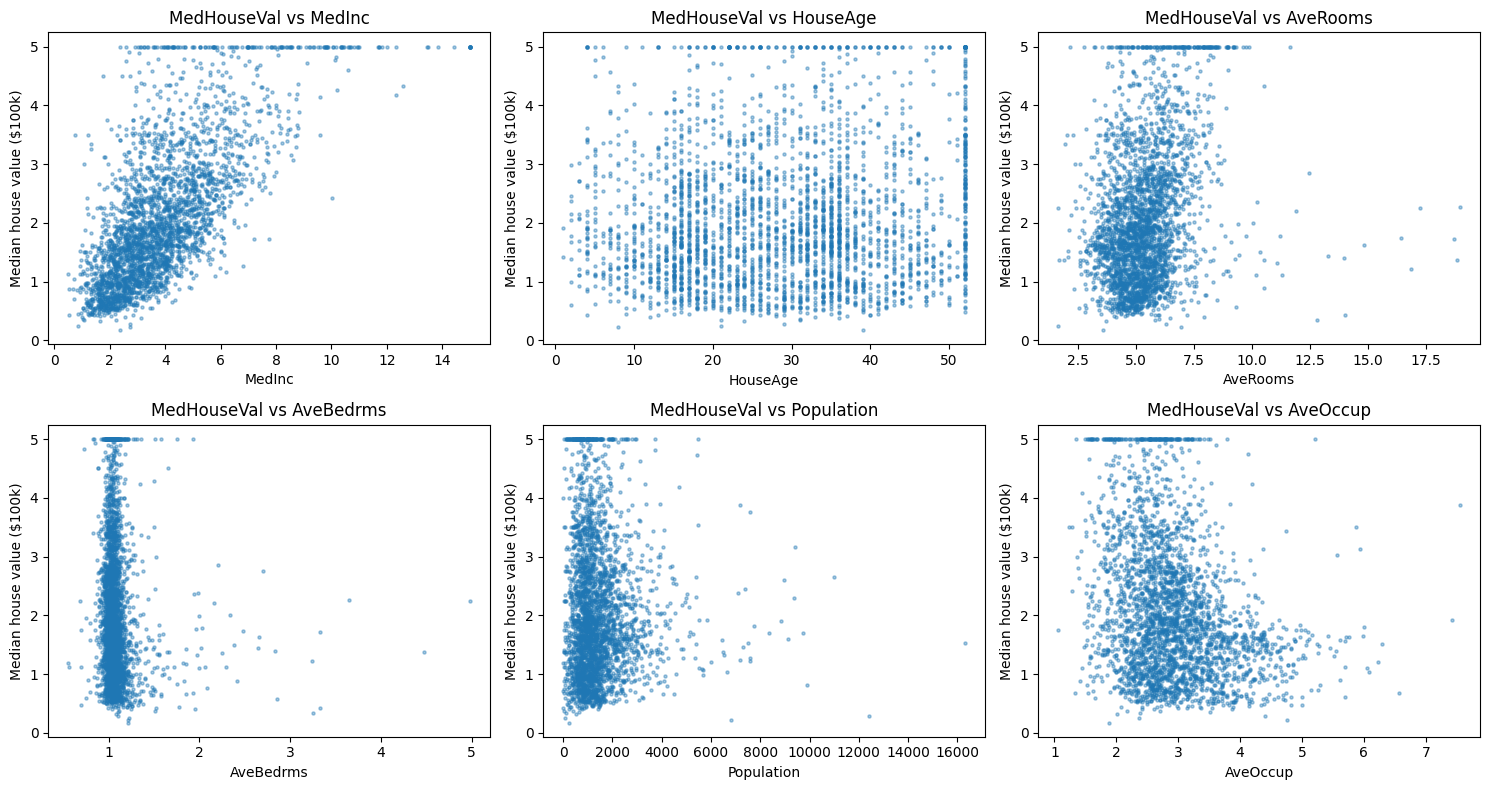

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
sample = df.sample(3000, random_state=SEED)   # sample only to keep the plots readable
for ax, f in zip(axes.ravel(), FEATURES):
    ax.scatter(sample[f], sample[TARGET], s=5, alpha=0.4)
    ax.set_title(f"{TARGET} vs {f}"); ax.set_xlabel(f); ax.set_ylabel("Median house value ($100k)")
plt.tight_layout(); plt.show()

**Observation:** `MedInc` shows a clear upward trend (higher income, higher value). `HouseAge` and `Population` show hardly any visible pattern. A horizontal line of points at 5.0 is the capping effect. Visible relationships do not prove causation.

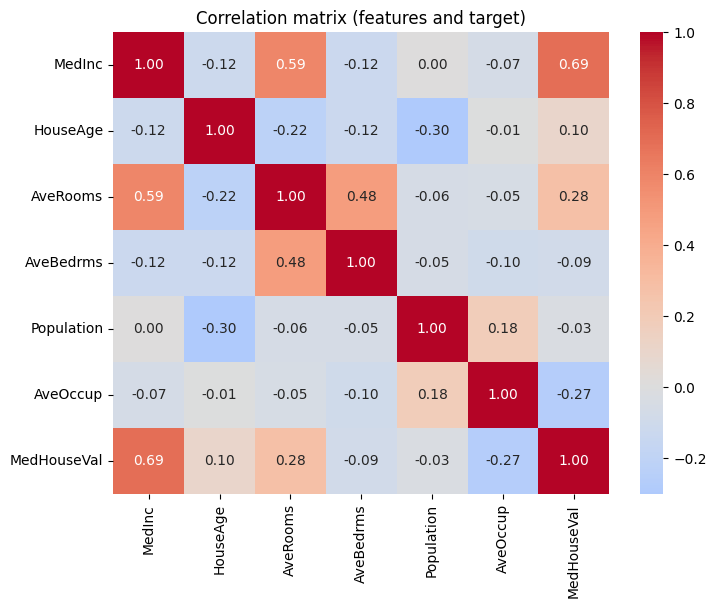

,MedHouseVal
MedInc,0.689647
AveRooms,0.277197
HouseAge,0.104735
Population,-0.025456
AveBedrms,-0.089816
AveOccup,-0.267288


In [6]:
corr = df[FEATURES + [TARGET]].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix (features and target)"); plt.show()
corr[TARGET].drop(TARGET).sort_values(ascending=False)

**Observation (fill after running):**
- Feature to target: `MedInc` has the strongest positive correlation, so it will be used as the single-feature baseline.
- Feature to feature: `AveRooms` and `AveBedrms` are strongly correlated with each other, a sign of **multicollinearity** (both describe house size). I will check this with VIF later.
- **Correlation does not prove causation.**

## 5. Manual calculation worksheet (Stage 4)
Six random observations and two features, X1 = MedInc and X2 = HouseAge. Solve the normal equations **(XᵀX) b = Xᵀy** by hand-style matrix algebra.

In [7]:
np.set_printoptions(precision=4, suppress=True)
m = df[["MedInc", "HouseAge", TARGET]].sample(6, random_state=SEED).round(3).reset_index(drop=True)
print("Sample table (X1 = MedInc, X2 = HouseAge, y = MedHouseVal):"); display(m)

X = np.column_stack([np.ones(len(m)), m["MedInc"], m["HouseAge"]])
y = m[TARGET].values.reshape(-1, 1)
print("Design matrix X (column of ones, X1, X2):\n", X)
print("\ny vector:\n", y)

XtX = X.T @ X
Xty = X.T @ y
print("\nX^T X =\n", XtX)
print("\nX^T y =\n", Xty)
print("\ndet(X^T X) =", np.linalg.det(XtX))
XtX_inv = np.linalg.inv(XtX)
print("\n(X^T X)^-1 =\n", XtX_inv)
b = XtX_inv @ Xty
print("\nb = (X^T X)^-1 X^T y =\n", b)
b0, b1, b2 = b.ravel()
print(f"\nFitted equation: y = {b0:.4f} + {b1:.4f}*MedInc + {b2:.4f}*HouseAge")

# Predict one observation and compute its residual
i = 0
pred = b0 + b1 * m.loc[i, "MedInc"] + b2 * m.loc[i, "HouseAge"]
print(f"\nObservation {i}: actual = {m.loc[i, TARGET]:.3f}, predicted = {pred:.3f}, residual = actual - predicted = {m.loc[i, TARGET] - pred:.3f}")

Sample table (X1 = MedInc, X2 = HouseAge, y = MedHouseVal):


,MedInc,HouseAge,MedHouseVal
0,2.264,52.0,1.285
1,2.971,27.0,0.609
2,4.793,36.0,2.726
3,3.821,46.0,2.736
4,1.281,42.0,0.875
5,4.108,36.0,1.812


Design matrix X (column of ones, X1, X2):
 [[ 1.     2.264 52.   ]
 [ 1.     2.971 27.   ]
 [ 1.     4.793 36.   ]
 [ 1.     3.821 46.   ]
 [ 1.     1.281 42.   ]
 [ 1.     4.108 36.   ]]

y vector:
 [[1.285]
 [0.609]
 [2.726]
 [2.736]
 [0.875]
 [1.812]]

X^T X =
 [[   6.       19.238   239.    ]
 [  19.238    70.0421  747.949 ]
 [ 239.      747.949  9905.    ]]

X^T y =
 [[ 10.043 ]
 [ 36.8031]
 [409.237 ]]

det(X^T X) = 17276.467677999888

(X^T X)^-1 =
 [[ 7.7758 -0.6826 -0.1361]
 [-0.6826  0.1337  0.0064]
 [-0.1361  0.0064  0.0029]]

b = (X^T X)^-1 X^T y =
 [[-2.718 ]
 [ 0.6737]
 [ 0.056 ]]

Fitted equation: y = -2.7180 + 0.6737*MedInc + 0.0560*HouseAge

Observation 0: actual = 1.285, predicted = 1.721, residual = actual - predicted = -0.436


**Worksheet:** copy the printed X, y, XᵀX, Xᵀy, inverse and b values into your handwritten/typed worksheet and show the matrix multiplication for at least a few entries by hand. For example, the top-left entry of XᵀX is n = 6, and the next entry in the first row is ΣX1. Show where each number comes from.

In [8]:
# Verification with scikit-learn on the same 6 rows
chk = LinearRegression().fit(m[["MedInc", "HouseAge"]], m[TARGET])
print("sklearn intercept, coefs :", chk.intercept_, chk.coef_)
print("manual   b0, b1, b2      :", b0, b1, b2)
print("Match:", np.allclose([chk.intercept_, *chk.coef_], [b0, b1, b2]))

sklearn intercept, coefs : -2.7180484804771785 [0.6737 0.056 ]
manual   b0, b1, b2      : -2.7180484804771883 0.6736648481576268 0.05603065495400295
Match: True


**Comment:** the two should match to many decimal places. Any tiny difference is floating-point rounding. With only 6 rows these coefficients are unstable and are for learning the mechanics only.

## 6. Split, baselines and models (Stage 4 and 5)

In [9]:
X_all, y_all = df[FEATURES], df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X_all, y_all, test_size=0.2, random_state=SEED)
print("Train:", X_train.shape, "| Test:", X_test.shape)

# Baseline 0: always predict the training mean
mean_pred = np.full(len(y_test), y_train.mean())
print("Mean-baseline test R2:", round(r2_score(y_test, mean_pred), 4), "| RMSE:", round(np.sqrt(mean_squared_error(y_test, mean_pred)), 4))

Train: (16425, 6) | Test: (4107, 6)
Mean-baseline test R2: -0.0001 | RMSE: 1.1523


In [10]:
# Baseline 1: single-feature model with the most correlated feature
best = corr[TARGET].drop(TARGET).abs().idxmax()
single = LinearRegression().fit(X_train[[best]], y_train)
print("Best single feature:", best)
print("Intercept:", round(single.intercept_, 4), "| Coefficient:", round(single.coef_[0], 4))
print("Single-feature test R2:", round(single.score(X_test[[best]], y_test), 4))

Best single feature: MedInc
Intercept: 0.45 | Coefficient: 0.4184
Single-feature test R2: 0.4736


In [11]:
# Multiple linear regression on all features, training data only
multi = LinearRegression().fit(X_train, y_train)
print("Intercept:", round(multi.intercept_, 4))
print(pd.Series(multi.coef_, index=FEATURES).round(4))

# Scaled version (scaler fitted on training data only) to compare coefficient sizes
scaler = StandardScaler().fit(X_train)
multi_s = LinearRegression().fit(scaler.transform(X_train), y_train)
std_coefs = pd.Series(multi_s.coef_, index=FEATURES)
print("\nStandardised coefficients (change in y per 1 standard deviation of the feature):")
print(std_coefs.round(4).sort_values(key=abs, ascending=False))

Intercept: 0.5115
MedInc        0.5425
HouseAge      0.0169
AveRooms     -0.2437
AveBedrms     1.0486
Population    0.0001
AveOccup     -0.3232
dtype: float64

Standardised coefficients (change in y per 1 standard deviation of the feature):
MedInc        1.0330
AveRooms     -0.3413
AveOccup     -0.2481
HouseAge      0.2127
AveBedrms     0.1939
Population    0.0689
dtype: float64


## 7. Interpret the equation (Stage 6)

In [12]:
terms = " ".join(f"{c:+.4f}*{f}" for f, c in zip(FEATURES, multi.coef_))
print(f"MedHouseVal = {multi.intercept_:.4f} {terms}")

MedHouseVal = 0.5115 +0.5425*MedInc +0.0169*HouseAge -0.2437*AveRooms +1.0486*AveBedrms +0.0001*Population -0.3232*AveOccup


**How to explain each coefficient** (write in your own words after seeing the numbers). Template: "Holding all other features constant, a one-unit increase in `MedInc` ($10,000) changes the predicted house value by b × $100,000."
- Do this for every feature, using the units from the data dictionary.
- **Intercept:** the predicted value when all features are 0. This is not realistic (no area has 0 income and 0 rooms), so the intercept is only a mathematical anchor.
- **Standardised coefficients:** raw coefficients depend on units, so use standardised ones to compare influence. The largest absolute value is the most influential in this model. This still does not prove causation.
- **Watch for:** a negative sign on `AveBedrms` or `AveRooms` that looks odd. This is typically caused by multicollinearity (see VIF below).

## 8. Predictions and evaluation on the test set (Stage 6)

In [13]:
y_pred = multi.predict(X_test)
cmp = pd.DataFrame({"Actual": y_test.values, "Predicted": y_pred, "Error (actual - predicted)": y_test.values - y_pred}).round(3)
cmp.head(10)

,Actual,Predicted,Error (actual - predicted)
0,1.285,1.822,-0.537
1,0.609,1.542,-0.933
2,2.726,2.601,0.125
3,2.736,2.538,0.198
4,0.875,1.376,-0.501
5,1.812,2.199,-0.387
6,1.945,2.017,-0.072
7,2.268,2.402,-0.134
8,1.754,1.312,0.442
9,2.750,2.754,-0.004


**Observation (fill):** note rows where the error is large. Typically these are expensive areas where the true value is capped at 5.0 or where the model underestimates.

In [14]:
def evaluate(y_true, y_hat, p):
    n = len(y_true)
    mse = mean_squared_error(y_true, y_hat)
    r2 = r2_score(y_true, y_hat)
    adj = 1 - (1 - r2) * (n - 1) / (n - p - 1)
    return {"MAE": mean_absolute_error(y_true, y_hat), "MSE": mse, "RMSE": np.sqrt(mse), "R2": r2, "Adjusted R2": adj}

res = pd.DataFrame({
    f"Single ({best})": evaluate(y_test, single.predict(X_test[[best]]), 1),
    f"Multiple ({len(FEATURES)} features)": evaluate(y_test, y_pred, len(FEATURES)),
}).T.round(4)
res

,MAE,MSE,RMSE,R2,Adjusted R2
Single (MedInc),0.6291,0.6989,0.8360,0.4736,0.4735
Multiple (6 features),0.5426,0.5346,0.7311,0.5974,0.5968


**Interpretation (write in your words):**
- **MAE** is the average absolute error. **MSE** is the average squared error and punishes big mistakes. **RMSE** is in target units (×$100,000), so an RMSE of 0.7 means a typical error of about $70,000.
- **R²** is the share of variance explained compared with predicting the mean (it can be negative on test data). **Adjusted R²** penalises features that add little.
- **Decision:** compare the two rows. If the multiple model clearly lowers RMSE and raises R² and adjusted R², the extra features are worth the complexity. If the gain is small, prefer the simpler model.

## 9. Residual analysis and assumptions (Stage 7)

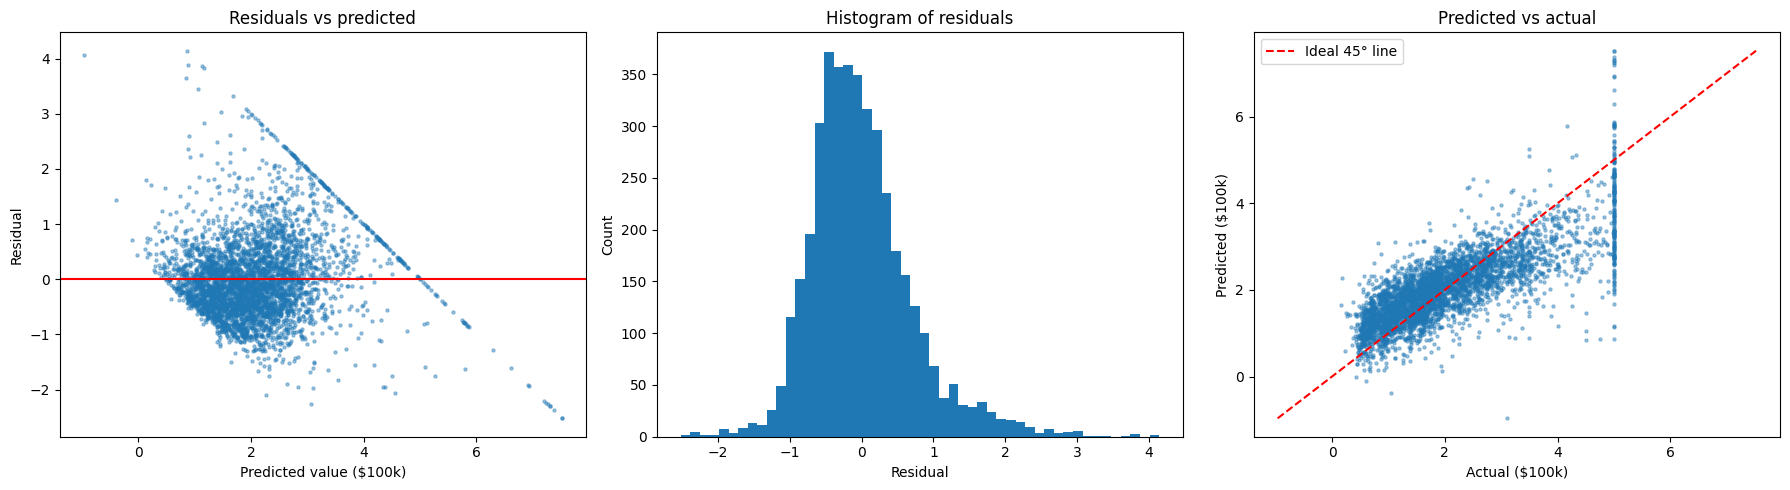

Residual skewness: 1.015 | mean residual: 0.0006


In [15]:
resid = y_test.values - y_pred
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
ax[0].scatter(y_pred, resid, s=5, alpha=0.4); ax[0].axhline(0, color="r")
ax[0].set_title("Residuals vs predicted"); ax[0].set_xlabel("Predicted value ($100k)"); ax[0].set_ylabel("Residual")
ax[1].hist(resid, bins=50); ax[1].set_title("Histogram of residuals"); ax[1].set_xlabel("Residual"); ax[1].set_ylabel("Count")
ax[2].scatter(y_test, y_pred, s=5, alpha=0.4)
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
ax[2].plot(lims, lims, "r--", label="Ideal 45° line")
ax[2].set_title("Predicted vs actual"); ax[2].set_xlabel("Actual ($100k)"); ax[2].set_ylabel("Predicted ($100k)"); ax[2].legend()
plt.tight_layout(); plt.show()
print("Residual skewness:", round(stats.skew(resid), 3), "| mean residual:", round(resid.mean(), 4))

**Observation (fill after seeing the plots):**
- Residuals vs predicted: a funnel shape means non-constant variance. Curvature means non-linearity.
- Histogram: roughly symmetric around 0 supports the normal-errors assumption; a long right tail is a sign of underestimating expensive areas.
- Predicted vs actual: points should hug the 45° line. The flat band at actual = 5.0 is the target cap.

In [16]:
# Variance Inflation Factor: VIF_j = 1 / (1 - R2_j), where R2_j comes from regressing feature j on all the others
vif = {}
for f in FEATURES:
    others = [c for c in FEATURES if c != f]
    r2_j = LinearRegression().fit(X_train[others], X_train[f]).score(X_train[others], X_train[f])
    vif[f] = 1 / (1 - r2_j)
pd.Series(vif, name="VIF").round(2).sort_values(ascending=False)

,VIF
AveRooms,2.99
MedInc,2.33
AveBedrms,1.93
HouseAge,1.18
Population,1.16
AveOccup,1.06


**VIF reading:** about 1 means no problem, above 5 is concerning, and above 10 is severe. If `AveRooms` and `AveBedrms` show high VIF, they carry overlapping information. Remedy: drop one, or combine them (for example a bedrooms-to-rooms ratio). Re-fit and compare test metrics.

**Assumption check** (state "reasonable" or "doubtful" for each, with a reason from your plots):
1. **Linearity:** residual plot curved? 2. **Independence of errors:** neighbouring block groups are spatially related, so this is doubtful. 3. **Constant variance:** funnel in the residual plot? 4. **Approximately normal errors:** histogram and skewness. 5. **No severe multicollinearity:** VIF.

In [17]:
# One improvement worth trying: drop the redundant feature with the highest VIF among rooms/bedrooms and compare
drop = "AveBedrms"
keep = [f for f in FEATURES if f != drop]
m2 = LinearRegression().fit(X_train[keep], y_train)
r2_res = evaluate(y_test, m2.predict(X_test[keep]), len(keep))
pd.concat([res, pd.DataFrame({f"Multiple without {drop}": r2_res}).T.round(4)])

,MAE,MSE,RMSE,R2,Adjusted R2
Single (MedInc),0.6291,0.6989,0.8360,0.4736,0.4735
Multiple (6 features),0.5426,0.5346,0.7311,0.5974,0.5968
Multiple without AveBedrms,0.5600,0.5561,0.7457,0.5812,0.5807


**Comment:** if test metrics barely change after dropping the redundant feature, the simpler and more stable model is better.

## 10. New prediction and conclusion (Stage 8)

In [18]:
print(df[FEATURES].describe().loc[["min", "max"]].T)   # check the new record is inside this range
new = pd.DataFrame([{"MedInc": 4.5, "HouseAge": 25, "AveRooms": 5.5, "AveBedrms": 1.1, "Population": 1200, "AveOccup": 3.0}])
p = multi.predict(new)[0]
print(f"Predicted median house value: {p:.3f} x $100,000 = about ${p*100000:,.0f}")

                 min           max
MedInc      0.499900     15.000100
HouseAge    1.000000     52.000000
AveRooms    0.846154     19.860000
AveBedrms   0.333333      4.980769
Population  3.000000  35682.000000
AveOccup    0.750000      9.954545
Predicted median house value: 2.293 x $100,000 = about $229,292


### Summary
- **Dataset:** California Housing (1990 census), cleaned to remove extreme outliers; 80:20 train/test split with `random_state=42`.
- **Model:** multiple linear regression on 6 features. Equation and coefficients are shown above.
- **Results:** (fill in) test RMSE, R² and adjusted R² of the multiple model versus the single-feature model and the mean baseline.
- **Key finding:** (fill in) which feature has the largest standardised coefficient and whether the extra features were worth it.

### Limitations and what NOT to use this for
- Do **not** use it to price an individual house or for any loan or investment decision. It predicts a neighbourhood median from 1990 data.
- Target capped at 5.0, so expensive areas are underestimated.
- Linear model: misses non-linear and location effects. Spatially correlated errors violate the independence assumption.
- Multicollinearity makes individual coefficients unreliable. Correlation is not causation.
- **Ethics:** wrong predictions could mislead buyers, sellers or planners, and could reinforce under-valuation of lower-priced areas. A prediction is an estimate, not a guarantee.

## Decision log
| Decision | Alternatives | Reason |
|---|---|---|
| Used California Housing | Kaggle house data, student marks | Reliable, citable, non-personal, no missing values |
| Removed rows with AveRooms≥20, AveBedrms≥5, AveOccup≥10 | Keep all, cap values | They are non-family or erroneous areas that distort the fit |
| Excluded Latitude and Longitude | Include them | A linear effect of coordinates is meaningless |
| Kept all 6 features at first, then tested dropping AveBedrms | Drop immediately | Let VIF and test metrics decide rather than assume |
| Baselines: mean predictor and best single feature | None | A model is only useful if it beats a simple benchmark |
| 80:20 split, seed 42, scaler fit on train only | k-fold CV | Required by the activity, prevents leakage and is reproducible |